# 01 — Pipeline CPU n°1 : PyTorch → ONNX → OpenVINO Runtime → CPU

| Couche | Technologie |
|---|---|
| Haut niveau | PyTorch, ResNet-18 + tête 10 classes |
| Format du modèle | ONNX (opset 17, batch fixe 10) |
| Middle level | OpenVINO Runtime (fusion d'opérateurs, sélection de kernels) |
| Bas niveau | oneDNN / kernels CPU Intel |
| Matériel | CPU |

Le notebook exporte le modèle en ONNX, mesure d'abord ONNX Runtime CPU comme
contrôle, puis convertit le même graphe ONNX pour OpenVINO Runtime.

In [1]:
%matplotlib inline
import json
import os
import sys
import time
from pathlib import Path

def _find_root() -> Path:
    p = Path.cwd().resolve()
    for candidate in [p, *p.parents]:
        if (candidate / "src" / "common.py").exists():
            return candidate
    return p

ROOT = _find_root()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TP_ROOT", str(ROOT))
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("TP_REPO_URL", "")
if IN_COLAB and REPO_URL and not (ROOT / "src" / "common.py").exists():
    import subprocess
    subprocess.run(["git", "clone", REPO_URL], check=True)
    ROOT = Path(REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")).resolve()
    os.chdir(ROOT)
    sys.path.insert(0, str(ROOT))
    os.environ["TP_ROOT"] = str(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from src import common as C

C.ensure_dirs()
C.set_seed()
torch.set_num_threads(int(os.environ.get("OMP_NUM_THREADS", "4")))
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("Racine du projet :", ROOT)
print("PyTorch :", torch.__version__, "| CUDA :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
print(f"Protocole : {C.N_IMAGES} images | batch={C.BATCH_SIZE} | {C.REPETITIONS} répétitions | warmup={C.WARMUP}")

Racine du projet : /workspace
PyTorch : 2.5.1+cu124 | CUDA : True
GPU : NVIDIA GeForce RTX 3050 Laptop GPU
Protocole : 50 images | batch=10 | 5 répétitions | warmup=5


In [2]:
def show(result_or_id):
    result = C.load_result(result_or_id) if isinstance(result_or_id, str) else result_or_id
    print(f"{result['label']}  |  device={result['device']}  |  backend={result['backend']}")
    display(pd.DataFrame(C.summary_rows(result)).round(4))
    print(f"Top-1 accuracy = {result['accuracy_top1'] * 100:.2f} %")

def bar_metric(ids, metric, std_metric, ylabel, title, color="#4C72B0"):
    df = pd.DataFrame(C.comparison_rows(ids))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(df["pipeline"], df[metric], yerr=df[std_metric], capsize=5, color=color)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=18)
    for i, value in enumerate(df[metric]):
        if value is not None:
            ax.text(i, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.show()
    return df

## 1. Données et modèle

images : (50, 32, 32, 3) uint8
tenseur prétraité : (50, 3, 224, 224) torch.float32
distribution : [5, 5, 5, 5, 5, 5, 5, 5, 5, 5]
classes : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


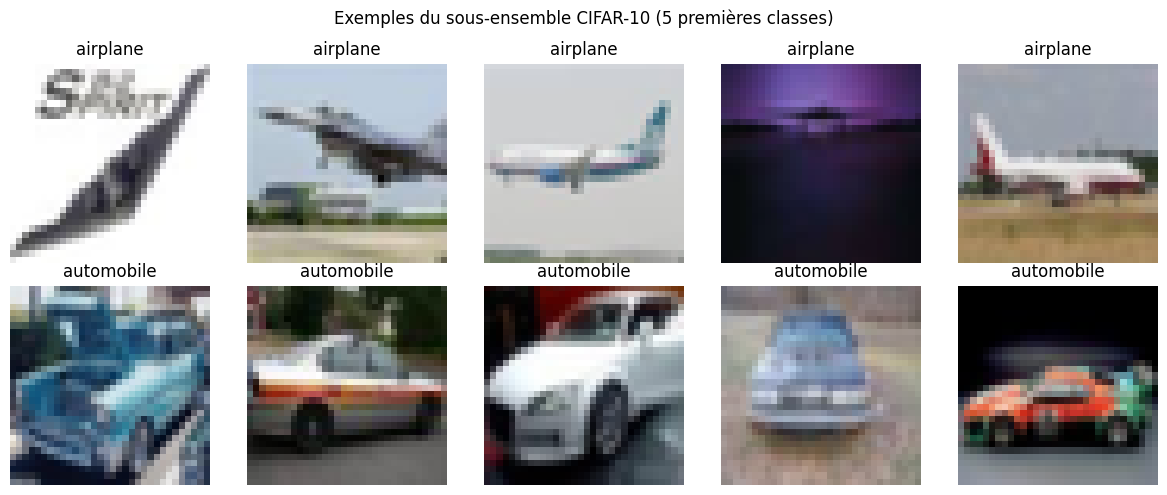

In [3]:
images, labels = C.load_subset()
x_cpu = C.preprocess_images(images, device="cpu")
print("images :", images.shape, images.dtype)
print("tenseur prétraité :", tuple(x_cpu.shape), x_cpu.dtype)
print("distribution :", np.bincount(labels, minlength=len(C.CLASSES)).tolist())
print("classes :", C.CLASSES)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, range(10)):
    ax.imshow(images[idx])
    ax.set_title(C.CLASSES[int(labels[idx])])
    ax.axis("off")
fig.suptitle("Exemples du sous-ensemble CIFAR-10 (5 premières classes)")
plt.tight_layout()
plt.show()

In [4]:
model = C.build_model("cpu")
n_params = sum(p.numel() for p in model.parameters())
print(f"ResNet-18 + tête 10 classes : {n_params/1e6:.2f} M paramètres")
print("Couche de classification :", model.fc)
print("Poids de la tête :", C.ARTIFACTS / "classifier_head.npz")

ResNet-18 + tête 10 classes : 11.18 M paramètres
Couche de classification : Linear(in_features=512, out_features=10, bias=True)
Poids de la tête : /workspace/artifacts/classifier_head.npz


## 2. Export ONNX

In [5]:
import onnx

onnx_path = C.ARTIFACTS / f"resnet18_cifar10_b{C.BATCH_SIZE}.onnx"
C.export_onnx(model, onnx_path)
print("ONNX :", onnx_path)
print(f"taille : {onnx_path.stat().st_size / 1e6:.2f} Mo")
onnx_model = onnx.load(str(onnx_path))
onnx.checker.check_model(onnx_model)
print("opset :", onnx_model.opset_import[0].version)
print("entrées :", [i.name for i in onnx_model.graph.input])
print("sorties :", [o.name for o in onnx_model.graph.output])
print("nombre de nœuds :", len(onnx_model.graph.node))

ONNX : /workspace/artifacts/resnet18_cifar10_b10.onnx
taille : 44.72 Mo
opset : 17
entrées : ['input']
sorties : ['logits']
nombre de nœuds : 49


## 3. Contrôle : ONNX Runtime CPU

ONNX Runtime exécute le graphe ONNX avec ses propres kernels CPU. Cette mesure
intermédiaire permet d'isoler l'effet du passage ONNX → OpenVINO.

In [6]:
import onnxruntime as ort

so = ort.SessionOptions()
so.intra_op_num_threads = C.CPU_THREADS
so.inter_op_num_threads = 1
sess_cpu = ort.InferenceSession(
    str(onnx_path), sess_options=so, providers=["CPUExecutionProvider"]
)
print("providers :", sess_cpu.get_providers())
print("input :", sess_cpu.get_inputs()[0].name, sess_cpu.get_inputs()[0].shape)
print("output :", sess_cpu.get_outputs()[0].name, sess_cpu.get_outputs()[0].shape)

fn = C.make_onnx_fn(sess_cpu, sess_cpu.get_inputs()[0].name)
records, summary, logits = C.run_benchmark(fn, x_cpu, "cpu")
C.save_result(
    "01a_cpu_onnxruntime", records, summary, logits, labels,
    device="cpu", backend="onnxruntime-cpu",
    notes="Contrôle ONNX Runtime CPU, même graphe ONNX.",
)
show("01a_cpu_onnxruntime")

providers : ['CPUExecutionProvider']
input : input [10, 3, 224, 224]
output : logits [10, 10]


ONNX Runtime (CPU, contrôle)  |  device=cpu  |  backend=onnxruntime-cpu


,Métrique,Moyenne,Écart-type,Min,Max
0,Débit (images/s),64.4942,5.5968,56.3952,70.2510
1,Latence (ms/image),15.6036,1.4189,14.2347,17.7320
2,Temps total (s),0.7802,0.0709,0.7117,0.8866
3,Énergie CPU (J),17.2805,1.2229,16.0509,19.0337
4,Énergie CPU/image (J),0.3456,0.0245,0.3210,0.3807
5,Top-1 accuracy,0.9400,0.0000,0.9400,0.9400


Top-1 accuracy = 94.00 %


## 4. Conversion et exécution OpenVINO

OpenVINO lit directement le fichier ONNX, applique ses optimisations
(fusion de convolutions/BN/ReLU, sélection de kernels oneDNN) et compile le
modèle pour le CPU.

In [7]:
import openvino as ov

core = ov.Core()
ov_model = ov.convert_model(str(onnx_path))
compiled = core.compile_model(
    ov_model,
    "CPU",
    {"PERFORMANCE_HINT": "THROUGHPUT", "INFERENCE_NUM_THREADS": str(C.CPU_THREADS)},
)
print("OpenVINO :", ov.__version__)
print("input :", compiled.input(0).shape)
print("output :", compiled.output(0).shape)

fn_ov = C.make_openvino_fn(compiled)
records, summary, logits_ov = C.run_benchmark(fn_ov, x_cpu, "cpu")
C.save_result(
    "01_cpu_onnx_openvino", records, summary, logits_ov, labels,
    device="cpu", backend="openvino",
    notes="ONNX -> OpenVINO Runtime CPU, PERFORMANCE_HINT=THROUGHPUT, 4 threads.",
)
show("01_cpu_onnx_openvino")

OpenVINO : 2025.1.0-18503-6fec06580ab-releases/2025/1
input : [10,3,224,224]
output : [10,10]


ONNX → OpenVINO (CPU)  |  device=cpu  |  backend=openvino


,Métrique,Moyenne,Écart-type,Min,Max
0,Débit (images/s),32.8152,0.1820,32.6318,33.1107
1,Latence (ms/image),30.4744,0.1683,30.2017,30.6449
2,Temps total (s),1.5237,0.0084,1.5101,1.5322
3,Énergie CPU (J),25.6738,0.2340,25.3129,25.9255
4,Énergie CPU/image (J),0.5135,0.0047,0.5063,0.5185
5,Top-1 accuracy,0.9400,0.0000,0.9400,0.9400


Top-1 accuracy = 94.00 %


## 5. Comparaison et intégrité des prédictions

In [8]:
ref = np.load(C.RESULTS / "00_reference_pytorch_cpu_logits.npy")
for rid in ["01a_cpu_onnxruntime", "01_cpu_onnx_openvino"]:
    r = C.load_result(rid)
    logits_r = np.load(C.RESULTS / f"{rid}_logits.npy")
    print(
        f"{r['label']:<32} Top-1={r['accuracy_top1']*100:5.2f} %  "
        f"accord avec PyTorch={C.prediction_agreement(logits_r, ref)*100:5.2f} %"
    )

ONNX Runtime (CPU, contrôle)     Top-1=94.00 %  accord avec PyTorch=100.00 %
ONNX → OpenVINO (CPU)            Top-1=94.00 %  accord avec PyTorch=100.00 %


,id,pipeline,device,backend,throughput_ips,throughput_std,latency_ms,latency_std,accuracy,energy_per_image_j,energy_per_image_std,energy_source
0,00_reference_pytorch_cpu,"PyTorch eager (CPU, réf.)",cpu,pytorch-eager,45.1760,2.6149,22.1964,1.3124,0.94,0.4723,0.0195,cpu_rapl
1,01a_cpu_onnxruntime,"ONNX Runtime (CPU, contrôle)",cpu,onnxruntime-cpu,64.4942,5.5968,15.6036,1.4189,0.94,0.3456,0.0245,cpu_rapl
2,01_cpu_onnx_openvino,ONNX → OpenVINO (CPU),cpu,openvino,32.8152,0.1820,30.4744,0.1683,0.94,0.5135,0.0047,cpu_rapl


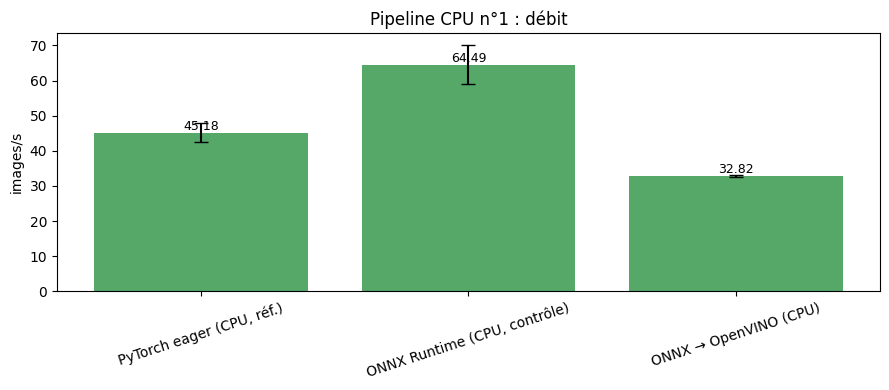

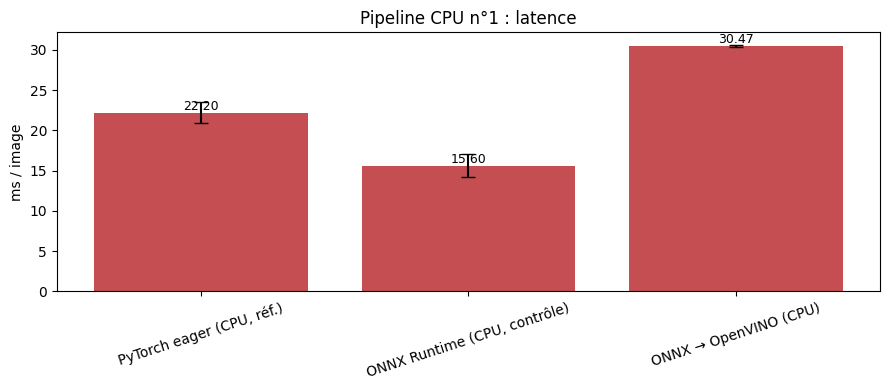

,id,pipeline,device,backend,throughput_ips,throughput_std,latency_ms,latency_std,accuracy,energy_per_image_j,energy_per_image_std,energy_source
0,00_reference_pytorch_cpu,"PyTorch eager (CPU, réf.)",cpu,pytorch-eager,45.175995,2.614870,22.196418,1.312366,0.94,0.472308,0.019506,cpu_rapl
1,01a_cpu_onnxruntime,"ONNX Runtime (CPU, contrôle)",cpu,onnxruntime-cpu,64.494193,5.596790,15.603620,1.418916,0.94,0.345610,0.024458,cpu_rapl
2,01_cpu_onnx_openvino,ONNX → OpenVINO (CPU),cpu,openvino,32.815245,0.181999,30.474388,0.168307,0.94,0.513476,0.004681,cpu_rapl


In [9]:
ids = ["00_reference_pytorch_cpu", "01a_cpu_onnxruntime", "01_cpu_onnx_openvino"]
display(pd.DataFrame(C.comparison_rows(ids)).round(4))
bar_metric(ids, "throughput_ips", "throughput_std", "images/s",
           "Pipeline CPU n°1 : débit", color="#55A868")
bar_metric(ids, "latency_ms", "latency_std", "ms / image",
           "Pipeline CPU n°1 : latence", color="#C44E52")

### Interprétation

Le tableau et les figures ci-dessus donnent le verdict expérimental. Dans nos
conditions (4 threads, batch de 10, station partagée avec d'autres conteneurs),
OpenVINO n'apporte pas de gain de débit par rapport à PyTorch eager et à ONNX
Runtime : la conversion et la sélection de kernels ne suffisent pas toujours à
compenser le coût du modèle et la charge CPU. C'est un résultat expérimental
valable : un runtime « optimisé » n'est pas magiquement plus rapide sur tout
matériel.

Le point non négociable est la qualité : la Top-1 reste à 94 % et l'accord des
prédictions avec PyTorch est de 100 %. Les optimisations de déploiement n'ont
donc pas dégradé les décisions du modèle. Il faudrait tester d'autres réglages
(nombre de threads, `PERFORMANCE_HINT=LATENCY`, quantization) pour chercher un
gain sur cette machine.
